(19375, 9)
['id', 'time', 'latitude', 'longitude', 'depth', 'mag', 'magType', 'place', 'yil']
                   Bölge  Toplam deprem  Mc  Mc üstü N  b-değeri  Std. hata
       Mersin ve çevresi             35 4.4          6      2.61      1.064
  Doğu Anadolu fay hattı           1238 4.5        344      1.10      0.059
DAF (Şub-Mar 2023 hariç)            795 4.5        185      1.05      0.077
             Tüm Türkiye          19375 2.9      12295      0.50      0.005


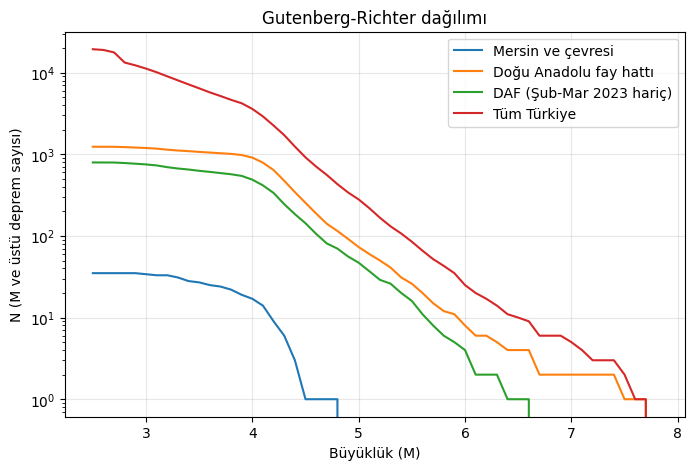

In [2]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt

URL = "https://raw.githubusercontent.com/nisanurguzel/deprem-sigorta-riskanalizi/refs/heads/main/01_Veri/deprem_temiz.csv"
df = pd.read_csv(URL)
df["time"] = pd.to_datetime(df["time"], utc=True, errors="coerce")
df = df.dropna(subset=["mag", "latitude", "longitude"])
print(df.shape)
print(df.columns.tolist())

def b_hesapla(mag):
    """Aki-Utsu en çok olabilirlik yöntemi"""
    mag = np.round(np.asarray(mag), 1)
    vals, cnt = np.unique(mag, return_counts=True)
    mc = vals[cnt.argmax()] + 0.2          # tamlık büyüklüğü (Mc)
    m = mag[mag >= mc]
    b = np.log10(np.e) / (m.mean() - (mc - 0.05))
    return mc, b, b / np.sqrt(len(m)), len(m)

# Bölgeler (kaba koordinat kutuları)
bolgeler = {
    "Mersin ve çevresi": df[df.latitude.between(36.0, 37.3) & df.longitude.between(33.0, 35.2)],
    "Doğu Anadolu fay hattı": df[df.latitude.between(36.0, 39.5) & df.longitude.between(36.0, 41.0)],
}
daf = bolgeler["Doğu Anadolu fay hattı"]
sub23 = (daf.time >= "2023-02-06") & (daf.time <= "2023-03-06")
bolgeler["DAF (Şub-Mar 2023 hariç)"] = daf[~sub23]
bolgeler["Tüm Türkiye"] = df

satirlar = []
for ad, d in bolgeler.items():
    mc, b, se, n = b_hesapla(d["mag"])
    satirlar.append([ad, len(d), round(mc, 1), n, round(b, 2), round(se, 3)])
tablo = pd.DataFrame(satirlar, columns=["Bölge", "Toplam deprem", "Mc", "Mc üstü N", "b-değeri", "Std. hata"])
print(tablo.to_string(index=False))

# Gutenberg-Richter grafiği
plt.figure(figsize=(8, 5))
for ad, d in bolgeler.items():
    mag = np.round(d["mag"].values, 1)
    esik = np.arange(2.5, mag.max() + 0.1, 0.1)
    kum = [(mag >= e).sum() for e in esik]
    plt.semilogy(esik, kum, label=ad)
plt.xlabel("Büyüklük (M)"); plt.ylabel("N (M ve üstü deprem sayısı)")
plt.title("Gutenberg-Richter dağılımı"); plt.legend(); plt.grid(alpha=0.3)
plt.savefig("b_degeri.png", dpi=150, bbox_inches="tight")
plt.show()

In [3]:
def b_sabit(mag, mc):
    m = np.round(np.asarray(mag), 1)
    m = m[m >= mc]
    if len(m) < 10:
        return np.nan, np.nan, len(m)
    b = np.log10(np.e) / (m.mean() - (mc - 0.05))
    return b, b / np.sqrt(len(m)), len(m)

yil_sayisi = (df["time"].max() - df["time"].min()).days / 365.25

satirlar = []
for ad, d in bolgeler.items():
    satir = [ad, len(d)]
    for mc in (4.0, 4.5):
        b, se, n = b_sabit(d["mag"], mc)
        satir += [n, round(b, 2) if b == b else "yetersiz", round(se, 2) if se == se else "-"]
    satir += [round((d["mag"] >= 4).sum() / yil_sayisi, 1), int((d["mag"] >= 5).sum())]
    satirlar.append(satir)

tablo2 = pd.DataFrame(satirlar, columns=[
    "Bölge", "Toplam",
    "N(M≥4.0)", "b(4.0)", "hata",
    "N(M≥4.5)", "b(4.5)", "hata ",
    "Yıllık M≥4", "M≥5 sayısı"])
print(tablo2.to_string(index=False))

                   Bölge  Toplam  N(M≥4.0)  b(4.0)  hata  N(M≥4.5)   b(4.5) hata   Yıllık M≥4  M≥5 sayısı
       Mersin ve çevresi      35        19    1.32  0.30         3 yetersiz     -         0.5           0
  Doğu Anadolu fay hattı    1238       980    0.88  0.03       344      1.1  0.06        26.6          92
DAF (Şub-Mar 2023 hariç)     795       544    0.90  0.04       185     1.05  0.08        14.7          56
             Tüm Türkiye   19375      4217    1.01  0.02      1245      1.1  0.03       114.3         341


In [5]:
import pandas as pd

for f in ["il_risk_skorlari.csv", "il_ozellikleri_nufus.csv"]:
    d = pd.read_csv(URL.replace("deprem_temiz.csv", f))
    print("=" * 50)
    print(f, d.shape)
    print(d.columns.tolist())
    print(d.head(8).to_string())

il_risk_skorlari.csv (81, 13)
['il', 'deprem_sayisi', 'maks_mag', 'm5_sayisi', 'ort_derinlik', 'deprem_sayisi_artcisiz', 'son10_egilim', 'son10_toplam', 'nufus', 'deprem_100bin', 'kume', 'tehlike_puani', 'risk_skoru']
              il  deprem_sayisi  maks_mag  m5_sayisi  ort_derinlik  deprem_sayisi_artcisiz  son10_egilim  son10_toplam    nufus  deprem_100bin  kume  tehlike_puani  risk_skoru
0  Kahramanmaraş          292.0       7.8       19.0          9.83                   100.0          7.90         264.0  1171298           8.54     3           1.40           5
1            Van          280.0       7.1       18.0          8.47                   280.0         -0.32          47.0  1141015          24.54     0           1.53           4
2        Malatya          152.0       6.0       19.0          9.61                    86.0          2.74         130.0   808692          10.63     3           1.17           5
3          Muğla          131.0       5.8       12.0         14.69            

In [6]:
import pandas as pd
r = pd.read_csv(URL.replace("deprem_temiz.csv", "il_risk_skorlari.csv"))

print(r.groupby("kume").agg(
    il_sayisi=("il", "count"),
    ort_tehlike=("tehlike_puani", "mean"),
    ort_deprem=("deprem_sayisi", "mean"),
    ort_egilim=("son10_egilim", "mean"),
    skor_min=("risk_skoru", "min"),
    skor_max=("risk_skoru", "max")).round(2))

print(r["risk_skoru"].value_counts().sort_index())

r["prim_katsayisi"] = (1 + (r["risk_skoru"] - 1) * 0.15).round(2)
print(r.sort_values("tehlike_puani", ascending=False)[
    ["il", "kume", "tehlike_puani", "risk_skoru", "prim_katsayisi"]].head(15).to_string(index=False))

      il_sayisi  ort_tehlike  ort_deprem  ort_egilim  skor_min  skor_max
kume                                                                    
0            28         0.61       57.82        0.13         4         4
1             1        -1.37       58.00        0.04         1         1
2            34        -0.15        9.24        0.01         3         3
3             5         0.98      150.60        3.76         5         5
4            13        -1.19        0.00        0.00         2         2
risk_skoru
1     1
2    13
3    34
4    28
5     5
Name: count, dtype: int64
           il  kume  tehlike_puani  risk_skoru  prim_katsayisi
          Van     0           1.53           4            1.45
Kahramanmaraş     3           1.40           5            1.60
      Malatya     3           1.17           5            1.60
       Elazığ     0           1.14           4            1.45
       Bingöl     0           1.11           4            1.45
      Denizli     0           0.88

In [7]:
import pandas as pd, numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

r = pd.read_csv(URL.replace("deprem_temiz.csv", "il_risk_skorlari.csv"))
kol = ["il", "kume", "risk_skoru", "tehlike_puani", "deprem_sayisi",
       "deprem_sayisi_artcisiz", "maks_mag", "m5_sayisi", "son10_egilim", "nufus"]

print("KUME 1 (tek ilden olusan):")
print(r[r.kume == 1][kol].to_string(index=False))
print("\nKUME 3 (skor 5):")
print(r[r.kume == 3][kol].to_string(index=False))
print("\nVan:")
print(r[r.il == "Van"][kol].to_string(index=False))

oz = ["deprem_sayisi_artcisiz", "maks_mag", "m5_sayisi",
      "ort_derinlik", "son10_egilim", "deprem_100bin"]
X = StandardScaler().fit_transform(r[oz])
print("\nMevcut kumelerin Silhouette:", round(silhouette_score(X, r["kume"]), 3))
for k in range(2, 8):
    lab = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X)
    print("k =", k, " Silhouette =", round(silhouette_score(X, lab), 3))

KUME 1 (tek ilden olusan):
     il  kume  risk_skoru  tehlike_puani  deprem_sayisi  deprem_sayisi_artcisiz  maks_mag  m5_sayisi  son10_egilim   nufus
Antalya     1           1          -1.37           58.0                    58.0       5.5        4.0          0.04 2619832

KUME 3 (skor 5):
           il  kume  risk_skoru  tehlike_puani  deprem_sayisi  deprem_sayisi_artcisiz  maks_mag  m5_sayisi  son10_egilim   nufus
Kahramanmaraş     3           5           1.40          292.0                   100.0       7.8       19.0          7.90 1171298
      Malatya     3           5           1.17          152.0                    86.0       6.0       19.0          2.74  808692
     Adıyaman     3           5           0.80          114.0                    45.0       5.6       11.0          2.78  632148
    Balıkesir     3           5           0.83          106.0                   106.0       6.1        5.0          2.92 1250610
        Hatay     3           5           0.71           89.0   

In [8]:
import pandas as pd, numpy as np, joblib
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.pipeline import Pipeline
from sklearn.metrics import silhouette_score
from google.colab import files

r = pd.read_csv(URL.replace("deprem_temiz.csv", "il_risk_skorlari.csv"))
oz = ["deprem_sayisi_artcisiz", "maks_mag", "m5_sayisi",
      "ort_derinlik", "son10_egilim", "deprem_100bin"]

pipe = Pipeline([("olcek", StandardScaler()),
                 ("kmeans", KMeans(n_clusters=5, n_init=10, random_state=42))])
pipe.fit(r[oz])
etiket = pipe.predict(r[oz])

# kümeleri ortalama tehlike puanına göre 1-5 skora çevir
sira = r.groupby(etiket)["tehlike_puani"].mean().sort_values().index
harita = {k: i + 1 for i, k in enumerate(sira)}

r2 = r.copy()
r2["kume"] = etiket
r2["risk_skoru"] = r2["kume"].map(harita)
r2["prim_katsayisi"] = (1 + (r2["risk_skoru"] - 1) * 0.15).round(2)

X = pipe.named_steps["olcek"].transform(r[oz])
print("Silhouette:", round(silhouette_score(X, etiket), 3))
print("\nSkora göre il sayısı:")
print(r2["risk_skoru"].value_counts().sort_index())
print("\nEski skor (satır) - yeni skor (sütun):")
print(pd.crosstab(r["risk_skoru"], r2["risk_skoru"]))
for s in range(1, 6):
    print(f"\nSkor {s}:", ", ".join(r2[r2.risk_skoru == s]["il"].head(15)))
print("\nAntalya:", int(r2[r2.il == "Antalya"]["risk_skoru"].iloc[0]),
      " Van:", int(r2[r2.il == "Van"]["risk_skoru"].iloc[0]))

joblib.dump({"pipeline": pipe, "kume_skor": harita, "ozellikler": oz}, "model.joblib")
r2.to_csv("il_risk_skorlari_v2.csv", index=False)
files.download("model.joblib")
files.download("il_risk_skorlari_v2.csv")

Silhouette: 0.488

Skora göre il sayısı:
risk_skoru
1     1
2    13
3    52
4    14
5     1
Name: count, dtype: int64

Eski skor (satır) - yeni skor (sütun):
risk_skoru  1   2   3   4  5
risk_skoru                  
1           1   0   0   0  0
2           0  13   0   0  0
3           0   0  34   0  0
4           0   0  17  11  0
5           0   0   1   3  1

Skor 1: Antalya

Skor 2: Artvin, Batman, Karabük, Edirne, Giresun, Kırklareli, Sinop, Mardin, Nevşehir, Uşak, Trabzon, Zonguldak, İstanbul

Skor 3: Hatay, Manisa, İzmir, Sakarya, Ankara, Gaziantep, Düzce, Çanakkale, Burdur, Osmaniye, Konya, Sivas, Hakkari, Bolu, Kocaeli

Skor 4: Van, Malatya, Muğla, Adıyaman, Balıkesir, Bingöl, Adana, Elazığ, Denizli, Erzurum, Kütahya, Afyon, Erzincan, Tunceli

Skor 5: Kahramanmaraş

Antalya: 1  Van: 4


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
import pandas as pd, numpy as np, joblib
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.cluster import KMeans
from sklearn.pipeline import Pipeline
from sklearn.metrics import silhouette_score
from google.colab import files

r = pd.read_csv(URL.replace("deprem_temiz.csv", "il_risk_skorlari.csv"))
oz = ["deprem_sayisi_artcisiz", "maks_mag", "m5_sayisi", "ort_derinlik",
      "son10_toplam", "son10_egilim", "deprem_100bin"]

def yumusat(a):
    a = np.asarray(a, dtype=float)
    return np.sign(a) * np.log1p(np.abs(a))

pipe = Pipeline([("log", FunctionTransformer(yumusat)),
                 ("olcek", StandardScaler()),
                 ("kmeans", KMeans(n_clusters=5, n_init=20, random_state=42))])
pipe.fit(r[oz])
etiket = pipe.predict(r[oz])

sira = r.groupby(etiket)["tehlike_puani"].mean().sort_values().index
harita = {int(k): i + 1 for i, k in enumerate(sira)}

r3 = r.copy()
r3["kume"] = etiket
r3["risk_skoru"] = r3["kume"].map(harita)
r3["prim_katsayisi"] = (1 + (r3["risk_skoru"] - 1) * 0.15).round(2)

X = pipe[:-1].transform(r[oz])
print("Silhouette:", round(silhouette_score(X, etiket), 3))
print("\nSkora göre il sayısı:")
print(r3["risk_skoru"].value_counts().sort_index())
for s in (5, 4):
    print(f"\nSkor {s}:", ", ".join(r3[r3.risk_skoru == s]["il"]))
print("\nSkor 1:", ", ".join(r3[r3.risk_skoru == 1]["il"]))
for il in ["Kahramanmaraş", "Hatay", "Malatya", "Adıyaman", "Van", "Antalya", "İstanbul", "Mersin"]:
    x = r3[r3.il == il]
    if len(x): print(il, "->", int(x.risk_skoru.iloc[0]))

joblib.dump({"pipeline": pipe, "kume_skor": harita, "ozellikler": oz}, "model.joblib")
r3.to_csv("il_risk_skorlari_v3.csv", index=False)
files.download("model.joblib")
files.download("il_risk_skorlari_v3.csv")

Silhouette: 0.412

Skora göre il sayısı:
risk_skoru
1    13
2     5
3    32
4    24
5     7
Name: count, dtype: int64

Skor 5: Kahramanmaraş, Malatya, Adıyaman, Balıkesir, Adana, Hatay, Gaziantep

Skor 4: Van, Muğla, Bingöl, Elazığ, Manisa, Denizli, Erzurum, Kütahya, İzmir, Sakarya, Erzincan, Ankara, Düzce, Çanakkale, Osmaniye, Konya, Sivas, Bolu, Bitlis, Tunceli, Çankırı, Çorum, Amasya, Tokat

Skor 1: Artvin, Batman, Karabük, Edirne, Giresun, Kırklareli, Sinop, Mardin, Nevşehir, Uşak, Trabzon, Zonguldak, İstanbul
Kahramanmaraş -> 5
Hatay -> 5
Malatya -> 5
Adıyaman -> 5
Van -> 4
Antalya -> 2
İstanbul -> 1
Mersin -> 3


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>